# Proyecto final — Fase 0: EDA y calidad de los datos de precipitación
**Valle del Cauca, 1981–2013 · estaciones (diario) vs. satélite (péntada)**

Antes de construir datos funcionales (bases B-spline, suavizado, FPCA) hay que entender qué se tiene en las manos. Una curva anual mal construida (con un total mensual metido en un día, con ceros que en realidad son faltantes, o con dos meses sin dato) arrastra el error a todas las fases siguientes: EDA funcional, comparación entre fuentes y la red KAN.

Este notebook responde, en orden:

1. **De dónde vienen los datos** y qué representa cada archivo.
2. **Cómo están**: estructura, tipos, unidades, periodos, estaciones.
3. **Nulos y faltantes**: los explícitos (celdas vacías) y los implícitos (días que no aparecen).
4. **Qué problemas tienen**: valores imposibles, totales mensuales en un solo día, ceros falsos, series copiadas, años incompletos.
5. **El satélite**: malla, unidades, péntadas, años incompletos.
6. **Qué podríamos hacer**: criterios propuestos y un embudo con el número de estaciones y de pares estación‑año antes y después de cada paso (lo pide el subcriterio 4.1 de la rúbrica).

> **Regla de este notebook:** aquí *no se borra nada de los archivos originales*. Se marcan banderas y se cuantifica el efecto de cada posible decisión. Las decisiones finales se toman (y justifican) en la fase de preprocesamiento.

## 0. Contexto del enunciado

| Fuente | Resolución temporal | Resolución espacial | Archivo(s) |
|---|---|---|---|
| Estaciones climáticas (pluviómetros) | Diaria | Puntual | `P_1930_1979.xlsx`, `P_1980_1990.csv`, `P_1991_2003.csv` |
| Producto satelital | Péntada (≈5 días) | Píxel de malla regular | `ImagenesSatelitePentadal/pptAAAANN.tif` |

Lo que el enunciado exige del preprocesamiento (subcriterio 4.1, nota 5):

- identificar **valores imposibles o errores de digitación**;
- identificar **totales mensuales registrados en un solo día**;
- identificar **ceros que en realidad son datos faltantes**;
- identificar **días faltantes y años incompletos**;
- **definir un criterio de cobertura mínima** por estación y año;
- decidir si se **agregan** datos (registros fuera del periodo para el FPCA, imputación) o se **eliminan**;
- **reportar el número de estaciones y de pares estación‑año antes y después de cada paso**;
- que el preprocesamiento **no use información de prueba**.

Cada sección de abajo apunta a uno de esos puntos.

## 1. Preparación

El notebook asume que está en la misma carpeta que los datos (`proyecto3/`). Si `rasterio` no está instalado, descomentar la primera línea de la celda siguiente.

In [1]:
# %pip install pandas numpy matplotlib openpyxl rasterio
from pathlib import Path
import zipfile, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import rasterio

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 9})

ROOT = Path.cwd()                      # carpeta proyecto3
OUT = ROOT / "eda_fase0"               # salidas de este notebook (no pisa eda_resultados/)
OUT.mkdir(exist_ok=True)
SAT_DIR = ROOT / "ImagenesSatelitePentadal"
if not SAT_DIR.exists():               # si solo está el zip, se descomprime
    with zipfile.ZipFile(ROOT / "ImagenesSatelitePentadal.zip") as z:
        z.extractall(ROOT)

PERIODO = (1981, 2013)                 # periodo del enunciado
print("Carpeta de trabajo:", ROOT.name)

Carpeta de trabajo: data


## 2. Lectura de los datos de estaciones

Los tres archivos se leen tal cual. El Excel (~1 millón de filas) tarda ~30 s; la primera vez se guarda una copia en caché (`eda_fase0/estaciones_crudas.pkl`) para que las siguientes ejecuciones sean inmediatas.

In [2]:
cache = OUT / "estaciones_crudas.pkl"
if cache.exists():
    raw = pd.read_pickle(cache)
else:
    t0 = time.time()
    hist = pd.read_excel(ROOT / "P_1930_1979.xlsx", sheet_name=0)
    print(f"Excel leído en {time.time()-t0:.0f} s")
    print("Hojas del Excel:", pd.ExcelFile(ROOT / "P_1930_1979.xlsx").sheet_names)
    print("SENSORNAME:", hist.SENSORNAME.value_counts().to_dict(), "| UNITS:", hist.UNITS.value_counts().to_dict())
    a = pd.read_csv(ROOT / "P_1980_1990.csv")
    b = pd.read_csv(ROOT / "P_1991_2003.csv")
    hist["archivo"], a["archivo"], b["archivo"] = "P_1930_1979.xlsx", "P_1980_1990.csv", "P_1991_2003.csv"
    cols = ["STATION_ID", "YEAR", "MONTH", "DAY", "VALUE", "archivo"]
    raw = pd.concat([hist[cols], a[cols], b[cols]], ignore_index=True)
    raw.to_pickle(cache)

for f, g in raw.groupby("archivo"):
    print(f"\n{f}: {g.shape[0]:,} filas")
    display(g.head(3))


P_1930_1979.xlsx: 984,226 filas


,STATION_ID,YEAR,MONTH,DAY,VALUE,archivo
0,2610000101,1952,1,18,0.0,P_1930_1979.xlsx
1,2610000101,1952,1,19,0.0,P_1930_1979.xlsx
2,2610000101,1952,1,20,0.0,P_1930_1979.xlsx



P_1980_1990.csv: 997,791 filas


,STATION_ID,YEAR,MONTH,DAY,VALUE,archivo
984226,2610000102,1980,1,1,2.0,P_1980_1990.csv
984227,2610000103,1980,1,1,5.0,P_1980_1990.csv
984228,2610000104,1980,1,1,8.0,P_1980_1990.csv



P_1991_2003.csv: 1,010,677 filas


,STATION_ID,YEAR,MONTH,DAY,VALUE,archivo
1982017,2610000101,1991,1,1,0.0,P_1991_2003.csv
1982018,2610000102,1991,1,1,0.0,P_1991_2003.csv
1982019,2610000103,1991,1,1,6.0,P_1991_2003.csv


### 2.1 Estructura y tipos

Cada fila es **una estación en un día**: `STATION_ID, YEAR, MONTH, DAY, VALUE`. El Excel trae además `SENSORNAME` (siempre *Pluviometer*) y `UNITS` (siempre *mm*), lo que confirma que `VALUE` es **precipitación diaria en mm** acumulada en 24 h. Los CSV tienen la misma estructura y rangos, así que se asume la misma unidad.

In [3]:
resumen = (raw.groupby("archivo")
              .agg(filas=("VALUE", "size"), estaciones=("STATION_ID", "nunique"),
                   anio_min=("YEAR", "min"), anio_max=("YEAR", "max"),
                   nulos_VALUE=("VALUE", lambda v: v.isna().sum()),
                   ceros_pct=("VALUE", lambda v: 100*(v == 0).mean()),
                   mediana=("VALUE", "median"), p99=("VALUE", lambda v: v.quantile(.99)),
                   maximo=("VALUE", "max")))
display(resumen.round(2))
print("Tipos:", raw.dtypes.to_dict())
print("Nulos explícitos por columna:", raw.isna().sum().to_dict())

,filas,estaciones,anio_min,anio_max,nulos_VALUE,ceros_pct,mediana,p99,maximo
archivo,,,,,,,,,
P_1930_1979.xlsx,984226,264,1930,1979,0,56.86,0.0,55.0,736.0
P_1980_1990.csv,997791,302,1980,1990,0,57.94,0.0,60.0,859375.0
P_1991_2003.csv,1010677,284,1991,2003,0,59.07,0.0,60.0,600.0


Tipos: {'STATION_ID': dtype('int64'), 'YEAR': dtype('int64'), 'MONTH': dtype('int64'), 'DAY': dtype('int64'), 'VALUE': dtype('float64'), 'archivo': <StringDtype(storage='python', na_value=nan)>}
Nulos explícitos por columna: {'STATION_ID': 0, 'YEAR': 0, 'MONTH': 0, 'DAY': 0, 'VALUE': 0, 'archivo': 0}


In [4]:
# Fechas válidas, duplicados y solapamiento de estaciones entre archivos
raw["DATE"] = pd.to_datetime(dict(year=raw.YEAR, month=raw.MONTH, day=raw.DAY), errors="coerce")
print("Fechas inválidas (p. ej. 31 de abril):", raw.DATE.isna().sum())
print("Filas duplicadas estación‑fecha:", raw.duplicated(["STATION_ID", "DATE"]).sum())

est = {f: set(g.STATION_ID) for f, g in raw.groupby("archivo")}
A, B, C = est["P_1930_1979.xlsx"], est["P_1980_1990.csv"], est["P_1991_2003.csv"]
print(f"\nEstaciones totales distintas: {len(A|B|C)}")
print(f"En 1980‑1990 y 1991‑2003: {len(B&C)} | solo en 1980‑1990: {len(B-C)} | solo en 1991‑2003: {len(C-B)}")
print(f"Del histórico que siguen en 1980‑1990: {len(A&B)} de {len(A)}")

# Cuenca según el código IDEAM: 26xx = Cauca (Magdalena‑Cauca); 52xx‑54xx = vertiente Pacífica
raw["cuenca"] = np.where(raw.STATION_ID.astype(str).str[:2] == "26", "Cauca", "Pacífico")
raw["subzona"] = raw.STATION_ID.astype(str).str[:4]
display(raw.groupby("cuenca").STATION_ID.nunique().rename("estaciones").to_frame().T)

Fechas inválidas (p. ej. 31 de abril): 0


Filas duplicadas estación‑fecha: 0



Estaciones totales distintas: 344
En 1980‑1990 y 1991‑2003: 261 | solo en 1980‑1990: 41 | solo en 1991‑2003: 23
Del histórico que siguen en 1980‑1990: 243 de 264


cuenca,Cauca,Pacífico
estaciones,272,72


**Lectura.** No hay celdas vacías ni fechas imposibles ni duplicados: los archivos "se ven limpios". Pero eso es engañoso: en precipitación los faltantes casi nunca vienen como `NaN`, vienen como **filas que no existen** (días ausentes) o **disfrazados de cero**. Eso se mide en las secciones 5 y 6.

El código de estación sigue la codificación IDEAM: los dos primeros dígitos indican el área hidrográfica. Esto importa climatológicamente: las estaciones **26xx** están en el valle interandino del río Cauca (régimen **bimodal**, ~1000–2000 mm/año), y las **52xx–54xx** en la vertiente del **Pacífico** (Dagua, Anchicayá, San Juan), una de las zonas más lluviosas del planeta (>5000 mm/año, lluvia casi todo el año). Usaremos esta división como proxy regional mientras no tengamos coordenadas.

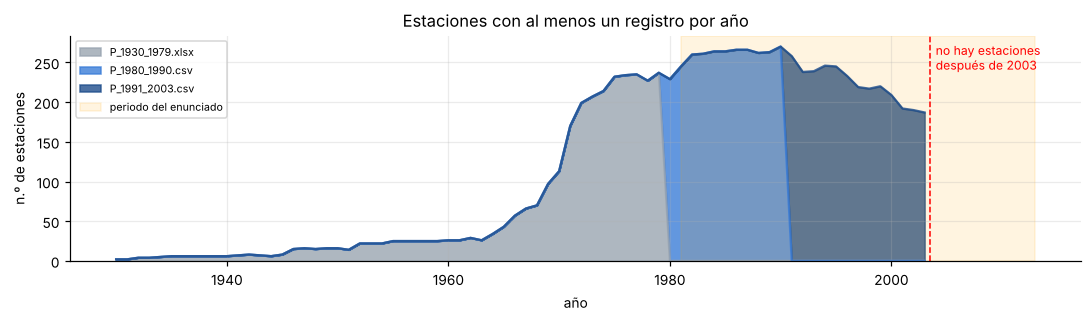

In [5]:
# ¿Cuántas estaciones reportan cada año? (cualquier registro)
act = raw.groupby(["YEAR", "archivo"]).STATION_ID.nunique().unstack()
fig, ax = plt.subplots(figsize=(10, 3))
act.plot(ax=ax, kind="area", stacked=True, alpha=.8, color=["#9aa5b1", "#3b7dd8", "#1f4e8c"])
ax.axvspan(*PERIODO, color="orange", alpha=.12, label="periodo del enunciado")
ax.axvline(2003.5, color="red", ls="--", lw=1)
ax.text(2004, ax.get_ylim()[1]*.85, "no hay estaciones\ndespués de 2003", color="red", fontsize=8)
ax.set(title="Estaciones con al menos un registro por año", xlabel="año", ylabel="n.º de estaciones")
ax.legend(loc="upper left", fontsize=7); plt.tight_layout(); plt.show()

**Lectura.** Las estaciones cubren 1930–2003; el satélite, 1981–2013. Entre 1981 y 2003 reportan entre ~190 y ~270 estaciones por año, con una **caída progresiva desde 1992 y más fuerte desde 2000** (cierre de estaciones). Después de 2003 no hay ninguna. Esto define el periodo útil para comparar fuentes: **1981–2003**.

### 2.2 Resolución de la medida (enteros vs. decimales)

Un pluviómetro convencional se lee a 0,1 mm. Si casi todo está en enteros, la serie fue **redondeada** al digitarse; si algunas estaciones o años tienen decimales y otras no, hay **cambios de protocolo** que afectan los días de lluvia muy débil (0,1–0,9 mm, que en enteros se vuelven 0 o 1).

Valores con decimales: 34,717 (1.16 %) en 107 estaciones


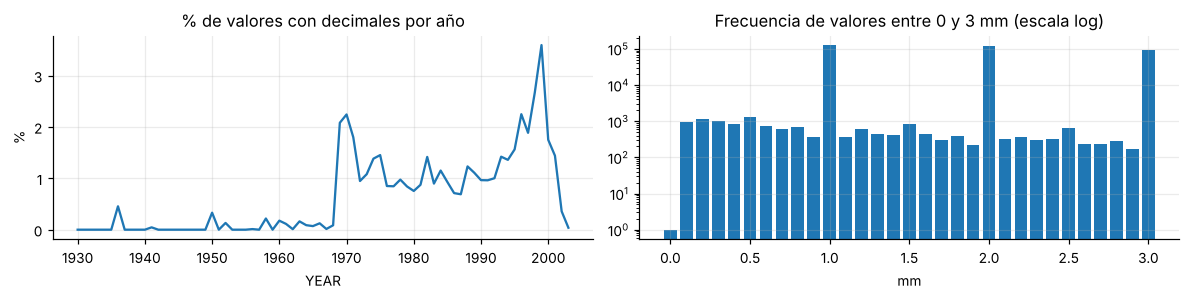

Días con lluvia < 1 mm: 7,679 | días con exactamente 1 mm: 127,542


In [6]:
raw["decimal"] = (raw.VALUE % 1) != 0
print(f"Valores con decimales: {raw.decimal.sum():,} ({100*raw.decimal.mean():.2f} %) en {raw.loc[raw.decimal,'STATION_ID'].nunique()} estaciones")
dec_anio = raw.groupby("YEAR").decimal.mean()*100
fig, ax = plt.subplots(1, 2, figsize=(11, 2.8))
dec_anio.plot(ax=ax[0]); ax[0].set(title="% de valores con decimales por año", ylabel="%")
peq = raw.loc[(raw.VALUE > 0) & (raw.VALUE <= 3), "VALUE"].round(1).value_counts().sort_index()
ax[1].bar(peq.index, peq.values, width=.08); ax[1].set_yscale("log")
ax[1].set(title="Frecuencia de valores entre 0 y 3 mm (escala log)", xlabel="mm"); plt.tight_layout(); plt.show()
print(f"Días con lluvia < 1 mm: {((raw.VALUE > 0) & (raw.VALUE < 1)).sum():,} | días con exactamente 1 mm: {(raw.VALUE == 1).sum():,}")

**Lectura.** El 98,8 % de los valores son enteros: la serie se digitó **redondeada a 1 mm**. Los decimales aparecen sobre todo después de 1970 y en algunas estaciones, lo que indica cambios de protocolo de digitación. Consecuencias: la lluvia de 0,1–0,9 mm casi no existe en los datos (se volvió 0 o 1), así que **la frecuencia de días lluviosos no es comparable entre estaciones/épocas** para umbrales < 1 mm. Para curvas anuales suavizadas esto pesa poco (se trabaja con cantidades), pero conviene usar un umbral de día lluvioso de **≥1 mm** en cualquier conteo.

## 3. Valores imposibles y errores de digitación

Referencias físicas para el Valle del Cauca: un día muy lluvioso en el valle ronda 80–150 mm; en el Pacífico puede superar 200–300 mm. Valores de **cientos de miles** son imposibles; valores de **500–950 mm** en un día son muy sospechosos y deben mirarse en su contexto (¿qué hay en los días alrededor?).

In [7]:
print(raw.VALUE.describe(percentiles=[.5, .9, .99, .999, .9999]).round(1).to_string())
print("\nNegativos:", (raw.VALUE < 0).sum())
umbrales = [150, 200, 300, 400, 500, 1000]
display(pd.DataFrame({f">{u} mm": [(raw.VALUE > u).sum()] for u in umbrales}, index=["n.º de días"]))
top = raw.nlargest(20, "VALUE")[["STATION_ID", "cuenca", "DATE", "VALUE", "archivo"]]
top["es_ultimo_dia_mes"] = top.DATE.dt.is_month_end
display(top)

count     2992694.0
mean            5.8
std           496.9
min             0.0
50%             0.0
90%            18.0
99%            60.0
99.9%         120.0
99.99%        199.0
max        859375.0

Negativos: 0


,>150 mm,>200 mm,>300 mm,>400 mm,>500 mm,>1000 mm
n.º de días,769,287,86,44,28,1


,STATION_ID,cuenca,DATE,VALUE,archivo,es_ultimo_dia_mes
1327944,2611600101,Cauca,1984-01-10,859375.0,P_1980_1990.csv,False
1132102,5421200201,Pacífico,1981-10-31,943.0,P_1980_1990.csv,True
1096577,5421200201,Pacífico,1981-05-31,896.0,P_1980_1990.csv,True
1089428,5421200201,Pacífico,1981-04-30,851.0,P_1980_1990.csv,True
1581214,5300000201,Pacífico,1986-09-30,838.0,P_1980_1990.csv,True
1110722,5421200201,Pacífico,1981-07-31,750.0,P_1980_1990.csv,True
963519,5421200201,Pacífico,1968-11-30,736.0,P_1930_1979.xlsx,True
962686,5421200201,Pacífico,1965-01-31,733.0,P_1930_1979.xlsx,True
1573505,5300000201,Pacífico,1986-08-31,732.0,P_1980_1990.csv,True
1557568,5300000201,Pacífico,1986-06-30,681.0,P_1980_1990.csv,True


In [8]:
# Contexto del valor imposible: ¿qué reporta la estación los días alrededor?
fila = raw.loc[raw.VALUE.idxmax()]
ctx = raw[(raw.STATION_ID == fila.STATION_ID) & raw.DATE.between(fila.DATE - pd.Timedelta(days=5), fila.DATE + pd.Timedelta(days=5))]
print(f"Estación {fila.STATION_ID}, {fila.DATE.date()}: {fila.VALUE:,.0f} mm")
display(ctx[["DATE", "VALUE"]].set_index("DATE").T)

Estación 2611600101, 1984-01-10: 859,375 mm


DATE,1984-01-05,1984-01-06,1984-01-07,1984-01-08,1984-01-09,1984-01-10,1984-01-11,1984-01-12,1984-01-13,1984-01-14,1984-01-15
VALUE,12.0,30.0,48.0,0.0,0.0,859375.0,36.0,0.0,0.0,0.0,0.0


**Lectura.** Hay un valor claramente imposible (859 375 mm, un error de digitación de varios dígitos pegados) y una cola de valores entre ~500 y ~950 mm que **caen casi siempre el último día del mes**. Eso no es una tormenta: es el siguiente problema.

## 4. Totales mensuales registrados en un solo día

Patrón típico de las planillas antiguas: el observador no reportó el dato diario y se digitó **el total del mes en el último día** (o en el primero). En los datos aparece como un **mes con un único registro** (el resto de los días ni siquiera existe) cuyo valor es del orden del total mensual de la estación.

Si se deja así, la curva funcional del año tendría un "pico" artificial de 500–900 mm en un día y cero información el resto del mes.

In [9]:
mes = (raw.groupby(["STATION_ID", "cuenca", "YEAR", "MONTH"])
          .agg(n_reg=("VALUE", "size"), total=("VALUE", "sum"), dia=("DAY", "max"))
          .reset_index())
mes["dias_mes"] = pd.to_datetime(dict(year=mes.YEAR, month=mes.MONTH, day=1)).dt.days_in_month
print(f"Meses estación‑mes con algún registro: {len(mes):,}; completos: {100*(mes.n_reg == mes.dias_mes).mean():.1f} %")
display(pd.cut(mes.n_reg / mes.dias_mes, [0, .05, .5, .8, .99, 1],
               labels=["1 registro", "≤50 %", "50–80 %", "80–99 %", "completo"]).value_counts().sort_index().to_frame("meses"))

uno = mes[mes.n_reg == 1].copy()
uno["en_ultimo_dia"] = uno.dia == uno.dias_mes
print(f"\nMeses con UN solo registro: {len(uno)} en {uno.STATION_ID.nunique()} estaciones; "
      f"{uno.en_ultimo_dia.sum()} caen el último día del mes, {(uno.dia == 1).sum()} el día 1")

# Comparar ese valor con el total mensual típico de la estación (meses completos)
clim = mes[mes.n_reg == mes.dias_mes].groupby(["STATION_ID", "MONTH"]).total.median().rename("total_mediano_mes")
uno = uno.join(clim, on=["STATION_ID", "MONTH"])
uno["razon_vs_mes_tipico"] = uno.total / uno.total_mediano_mes
print("Razón valor único / total mensual mediano de la estación (mediana):", round(uno.razon_vs_mes_tipico.median(), 2))

Meses estación‑mes con algún registro: 99,458; completos: 95.8 %


,meses
1 registro,212
≤50 %,664
50–80 %,889
80–99 %,2369
completo,95324



Meses con UN solo registro: 212 en 59 estaciones; 188 caen el último día del mes, 14 el día 1
Razón valor único / total mensual mediano de la estación (mediana): 0.91


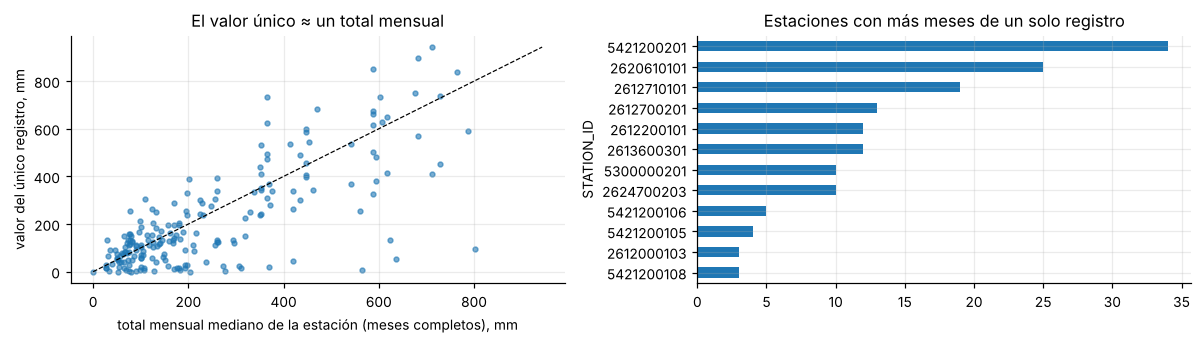

,STATION_ID,cuenca,YEAR,MONTH,n_reg,total,dia,dias_mes,en_ultimo_dia,total_mediano_mes,razon_vs_mes_tipico
97474,5421200201,Pacífico,1981,10,1,943.0,31,31,True,711.0,1.326301
97469,5421200201,Pacífico,1981,5,1,896.0,31,31,True,683.0,1.311859
97468,5421200201,Pacífico,1981,4,1,851.0,30,30,True,588.0,1.447279
84922,5300000201,Pacífico,1986,9,1,838.0,30,30,True,764.0,1.096859
97471,5421200201,Pacífico,1981,7,1,750.0,31,31,True,675.0,1.111111
97367,5421200201,Pacífico,1968,11,1,736.0,30,30,True,728.6,1.010156
97333,5421200201,Pacífico,1965,1,1,733.0,31,31,True,365.0,2.008219
84921,5300000201,Pacífico,1986,8,1,732.0,31,31,True,602.0,1.215947
84919,5300000201,Pacífico,1986,6,1,681.0,30,30,True,469.5,1.450479
97360,5421200201,Pacífico,1968,4,1,673.0,30,30,True,588.0,1.144558


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ok = uno.dropna(subset=["total_mediano_mes"])
ax[0].scatter(ok.total_mediano_mes, ok.total, s=10, alpha=.6)
lim = [0, max(ok.total.max(), ok.total_mediano_mes.max())]
ax[0].plot(lim, lim, "k--", lw=.8); ax[0].set(xlabel="total mensual mediano de la estación (meses completos), mm",
                                             ylabel="valor del único registro, mm", title="El valor único ≈ un total mensual")
raw_dias = raw[raw.VALUE > 0].groupby(raw.DATE.dt.is_month_end).VALUE.describe()[["mean", "75%", "max"]]
(uno.groupby("STATION_ID").size().sort_values(ascending=False).head(12)
    .plot.barh(ax=ax[1], title="Estaciones con más meses de un solo registro"))
ax[1].invert_yaxis(); plt.tight_layout(); plt.show()
display(uno.sort_values("total", ascending=False).head(10))

**También pueden aparecer acumulados "parciales":** una racha de días ausentes seguida de un valor muy grande (el observador volvió y registró lo acumulado de varios días). Se marca un día como *acumulado sospechoso* si viene después de ≥3 días sin registro y supera el percentil 99 de los días lluviosos de esa estación.

In [11]:
def calendario(df):
    # Reindexa cada estación a calendario diario completo entre su primer y último registro
    out = []
    for sid, g in df.groupby("STATION_ID"):
        s = g.set_index("DATE").VALUE.sort_index()
        s = s.reindex(pd.date_range(s.index.min(), s.index.max(), freq="D"))
        out.append(pd.DataFrame({"STATION_ID": sid, "DATE": s.index, "VALUE": s.values}))
    return pd.concat(out, ignore_index=True)

cal = calendario(raw)
cal["cuenca"] = np.where(cal.STATION_ID.astype(str).str[:2] == "26", "Cauca", "Pacífico")
cal["falta"] = cal.VALUE.isna()
# días ausentes consecutivos justo antes de cada día
grp = (~cal.falta).groupby(cal.STATION_ID).cumsum()
cal["huecos_previos"] = cal.groupby([cal.STATION_ID, grp]).falta.cumsum().groupby(cal.STATION_ID).shift(1).fillna(0)
p99 = cal[cal.VALUE > 0].groupby("STATION_ID").VALUE.quantile(.99).rename("p99_est")
cal = cal.join(p99, on="STATION_ID")
acum = cal[(~cal.falta) & (cal.huecos_previos >= 3) & (cal.VALUE > cal.p99_est)]
print(f"Días sospechosos de ser acumulados tras un hueco: {len(acum)} en {acum.STATION_ID.nunique()} estaciones")
display(acum.sort_values("VALUE", ascending=False).head(8)[["STATION_ID", "DATE", "VALUE", "huecos_previos", "p99_est"]])

Días sospechosos de ser acumulados tras un hueco: 426 en 131 estaciones


,STATION_ID,DATE,VALUE,huecos_previos,p99_est
3134883,5421200201,1981-10-31,943.0,30.0,135.0
3134730,5421200201,1981-05-31,896.0,30.0,135.0
3134699,5421200201,1981-04-30,851.0,29.0,135.0
2705195,5300000201,1986-09-30,838.0,29.0,133.0
3134791,5421200201,1981-07-31,750.0,30.0,135.0
3130165,5421200201,1968-11-30,736.0,29.0,135.0
3128766,5421200201,1965-01-31,733.0,761.0,135.0
2705165,5300000201,1986-08-31,732.0,30.0,133.0


**Lectura.**
- Hay **212 meses con un único registro** en 59 estaciones; 188 caen el último día del mes. Su valor es, en mediana, el 91 % del total mensual típico de la estación (los puntos siguen la diagonal): **son totales mensuales, no lluvias diarias**. Esto explica casi toda la cola de valores de 500–950 mm/día de la §3.
- Se concentran en pocas estaciones (5421200201, 2620610101, 2612710101…) y sobre todo antes de 1981; en 1981–2003 afectan pocos meses.
- **Qué hacer:** tratar ese mes como **faltante** a escala diaria. El total sí es informativo: si se quisiera, podría repartirse según el patrón diario de estaciones vecinas (desagregación), pero eso es imputación y hay que justificarlo. La opción simple y defendible es marcarlo como faltante.
- Los **426 "acumulados tras hueco"** son más ambiguos (muchos son lluvias fuertes reales después de pocos días sin registro). Se dejan **solo como bandera** y no se eliminan en el embudo; su efecto en una curva suavizada es local.

## 5. Días faltantes y años incompletos

Aquí aparecen los faltantes de verdad. Se reconstruye el calendario completo de cada estación (del primer al último registro) y se cuentan los días ausentes. Interesa:

- **cuántos** días faltan por estación‑año (cobertura);
- **cómo** faltan: días sueltos (fáciles de manejar en el suavizado) o **bloques largos** (meses enteros, que rompen la curva anual);
- **cuándo** faltan: si los faltantes se concentran en una temporada, el sesgo no es aleatorio.

In [12]:
cal["YEAR"] = cal.DATE.dt.year
cal["MONTH"] = cal.DATE.dt.month

def max_racha(b):
    b = np.asarray(b, dtype=int)
    if b.sum() == 0: return 0
    d = np.diff(np.r_[0, b, 0]); return int((np.flatnonzero(d == -1) - np.flatnonzero(d == 1)).max())

# Cobertura estación‑año sobre el AÑO CALENDARIO COMPLETO (no solo entre el primer y último registro)
cal_full = []
for sid, g in raw.groupby("STATION_ID"):
    s = g.set_index("DATE").VALUE
    for y in sorted(g.YEAR.unique()):
        idx = pd.date_range(f"{y}-01-01", f"{y}-12-31")
        v = s.reindex(idx)
        cal_full.append((sid, y, len(idx), int(v.notna().sum()), max_racha(v.isna()),
                         int((v.groupby(idx.month).count() >= 20).sum())))
cob = pd.DataFrame(cal_full, columns=["STATION_ID", "YEAR", "dias_anio", "dias_con_dato", "max_hueco", "meses_ok"])
cob["cobertura"] = cob.dias_con_dato / cob.dias_anio
cob["cuenca"] = np.where(cob.STATION_ID.astype(str).str[:2] == "26", "Cauca", "Pacífico")
print(f"Pares estación‑año con al menos un dato: {len(cob):,}")
display(cob.cobertura.describe(percentiles=[.05, .1, .25, .5]).round(3).to_frame().T)

Pares estación‑año con al menos un dato: 8,657


,count,mean,std,min,5%,10%,25%,50%,max
cobertura,8657.0,0.946,0.155,0.003,0.63,0.837,0.995,1.0,1.0


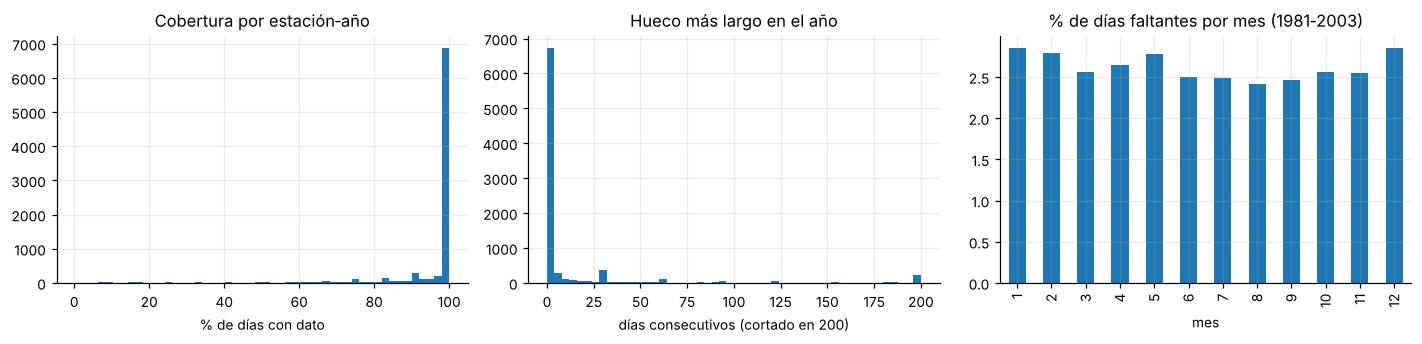

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
ax[0].hist(cob.cobertura*100, bins=50); ax[0].set(title="Cobertura por estación‑año", xlabel="% de días con dato")
ax[1].hist(cob.max_hueco.clip(upper=200), bins=50); ax[1].set(title="Hueco más largo en el año", xlabel="días consecutivos (cortado en 200)")
# estacionalidad de los faltantes (1981‑2003)
sub = cob.query("1981 <= YEAR <= 2003")[["STATION_ID", "YEAR"]]
tmp = cal.merge(sub, on=["STATION_ID", "YEAR"])
(tmp.groupby("MONTH").falta.mean()*100).plot.bar(ax=ax[2], title="% de días faltantes por mes (1981‑2003)")
ax[2].set_xlabel("mes"); plt.tight_layout(); plt.show()

/tmp/ipykernel_1331/3970849120.py:4: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  per = per.loc[per.mean(1).sort_values(ascending=False).index]


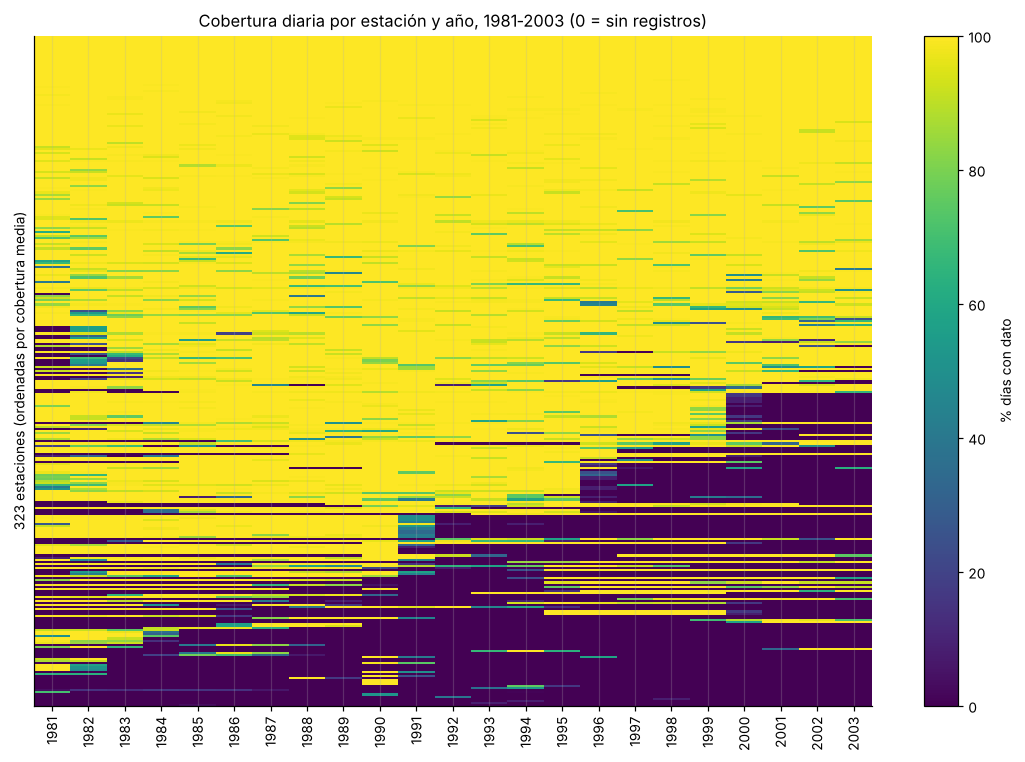

In [14]:
# Mapa de calor estación × año en el periodo con estaciones (1981‑2003)
per = cob.query("1981 <= YEAR <= 2003").pivot(index="STATION_ID", columns="YEAR", values="cobertura")
per = per.reindex(columns=range(1981, 2004)).fillna(0)
per = per.loc[per.mean(1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(per.values*100, aspect="auto", cmap="viridis", vmin=0, vmax=100, interpolation="nearest")
ax.set_xticks(range(per.shape[1])); ax.set_xticklabels(per.columns, rotation=90)
ax.set_yticks([]); ax.set(ylabel=f"{per.shape[0]} estaciones (ordenadas por cobertura media)",
                          title="Cobertura diaria por estación y año, 1981‑2003 (0 = sin registros)")
plt.colorbar(im, ax=ax, label="% días con dato"); plt.tight_layout(); plt.show()

In [15]:
# Años incompletos: ¿cómo se distribuyen los pares estación‑año 1981‑2003 por tipo de faltante?
c81 = cob.query("1981 <= YEAR <= 2003").copy()
c81["tipo"] = pd.cut(c81.cobertura, [-.01, .5, .8, .9, .99, 1],
                     labels=["<50 % (año casi vacío)", "50–80 %", "80–90 %", "90–99 %", "≥99 % (completo)"])
display(pd.crosstab(c81.tipo, c81.max_hueco > 30, margins=True).rename(columns={False: "hueco ≤30 d", True: "hueco >30 d"}))

max_hueco,hueco ≤30 d,hueco >30 d,All
tipo,,,
<50 % (año casi vacío),9,155,164
50–80 %,14,163,177
80–90 %,27,114,141
90–99 %,473,91,564
≥99 % (completo),4468,0,4468
All,4991,523,5514


**Lectura.**
- **Los faltantes son implícitos**: no hay `NaN` en los archivos, pero en 1981–2003 hay 5 514 pares estación‑año con algún registro y solo 4 468 (81 %) tienen el año completo (≥99 % de días).
- La distribución es **bimodal**: la gran mayoría de años están completos o casi, y hay una cola de años muy incompletos (164 con menos del 50 % de los días). Los años intermedios casi siempre tienen **un hueco largo** (>30 días seguidos), no días sueltos. Eso es lo que más daña una curva anual: si falta abril‑mayo, la base B‑spline "inventa" el primer pico de lluvia.
- Los faltantes se reparten **parejo entre meses** (2,4–2,9 %): no se concentran en una temporada, así que eliminarlos no sesga por estación del año.
- En el mapa de calor se ve que muchas estaciones **cierran hacia 1999–2000** y otras **arrancan tarde**: las estaciones no comparten los mismos años, lo que hay que tener en cuenta al hacer particiones temporales de entrenamiento y prueba.

## 6. Ceros que en realidad son faltantes

Este es el problema más difícil. En el Valle, julio‑agosto es seco y un cero puede ser real. Pero un cero también puede significar "no se midió" (planilla en blanco digitada como 0). Señales que usamos, de la más fuerte a la más débil:

1. **Años copiados**: dos estaciones distintas con el mismo vector de 365 valores (imposible físicamente; es un error de digitación/copiado).
2. **Rachas largas de ceros mientras la región llueve**: para cada racha de ≥30 días en cero calculamos `p_lluvia` = fracción media de *las demás estaciones de la misma cuenca* que registraron lluvia esos días. Una sequía real afecta a la región (`p_lluvia` bajo); un cero falso no (`p_lluvia` alto).
3. **Rachas idénticas en varias estaciones** (mismas fechas exactas de inicio y fin).
4. **Estación‑año completamente en cero**, o meses de temporada lluviosa (abr‑may, oct‑nov) en cero total.
5. **Rachas larguísimas en el Pacífico**, donde llueve casi todos los días.

In [16]:
# 6.1 Años idénticos entre estaciones distintas
cal["doy"] = cal.DATE.dt.dayofyear
piv = cal.pivot_table(index=["STATION_ID", "YEAR"], columns="doy", values="VALUE", aggfunc="first")
piv = piv[(piv.notna().sum(1) > 300) & ((piv.fillna(0) > 0).sum(1) > 20)]   # años con datos y con lluvia
firma = piv.fillna(-1).round(1).apply(lambda r: hash(tuple(r)), axis=1)
copias = firma[firma.duplicated(keep=False)].rename("firma").reset_index().sort_values(["firma", "YEAR"])
copias["grupo"] = copias.groupby("firma").ngroup()
print(f"Pares estación‑año que son copia exacta de otra estación: {len(copias)} ({copias.grupo.nunique()} grupos)")
display(copias.groupby("grupo").agg(estaciones=("STATION_ID", lambda s: ", ".join(map(str, s))), anio=("YEAR", "first")))

Pares estación‑año que son copia exacta de otra estación: 12 (6 grupos)


/tmp/ipykernel_1331/1587934802.py:4: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  piv = piv[(piv.notna().sum(1) > 300) & ((piv.fillna(0) > 0).sum(1) > 20)]   # años con datos y con lluvia
/tmp/ipykernel_1331/1587934802.py:4: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  piv = piv[(piv.notna().sum(1) > 300) & ((piv.fillna(0) > 0).sum(1) > 20)]   # años con datos y con lluvia


,estaciones,anio
grupo,,
0,"5421200202, 5421200207",1987
1,"2612000202, 5300900101",1969
2,"5301400106, 5301400109",1973
3,"5301400106, 5301400109",1974
4,"5301400106, 5301400109",1977
5,"5301400106, 5301400109",1975


**Lectura.** Hay **12 pares estación‑año que son copias exactas** de otra estación (365 valores idénticos). El caso 2612000202 (cuenca del Cauca) = 5300900101 (Pacífico) en 1969 es físicamente imposible: son climas distintos. 5301400106 y 5301400109 comparten cuatro años completos. No se puede saber cuál es el original, así que la opción defendible es **eliminar todas las copias**. Solo un grupo (1987) cae dentro de 1981–2003.

In [17]:
# 6.2 Rachas de ceros y contraste regional
def rachas_cero(g, minimo=30):
    v = (g.VALUE.values == 0).astype(int)
    d = np.diff(np.r_[0, v, 0]); ini, fin = np.flatnonzero(d == 1), np.flatnonzero(d == -1)
    L = fin - ini; k = L >= minimo
    return pd.DataFrame({"ini": g.DATE.values[ini[k]], "fin": g.DATE.values[fin[k]-1], "dias": L[k]})

rz = cal.groupby("STATION_ID", group_keys=True).apply(rachas_cero).reset_index(level=0).reset_index(drop=True)
rz["cuenca"] = np.where(rz.STATION_ID.astype(str).str[:2] == "26", "Cauca", "Pacífico")

hum = cal.dropna(subset=["VALUE"]).assign(llueve=lambda x: x.VALUE > 0).groupby(["cuenca", "DATE"]).llueve.agg(["sum", "count"])
def p_lluvia(r):
    h = hum.loc[r.cuenca].loc[r.ini:r.fin]
    return (h["sum"] / (h["count"] - 1).clip(lower=1)).mean()   # excluye la propia estación (que tiene 0)
rz["p_lluvia_region"] = rz.apply(p_lluvia, axis=1)
rz["racha_repetida"] = rz.duplicated(["ini", "fin"], keep=False)
rz["mes_inicio"] = pd.to_datetime(rz.ini).dt.month
print(f"Rachas de ≥30 días en cero: {len(rz)} en {rz.STATION_ID.nunique()} estaciones; "
      f"≥60 días: {(rz.dias >= 60).sum()}; con fechas idénticas en otra estación: {rz.racha_repetida.sum()}")
display(pd.crosstab(rz.cuenca, pd.cut(rz.p_lluvia_region, [0, .2, .3, .4, .5, 1]), margins=True))

Rachas de ≥30 días en cero: 1979 en 269 estaciones; ≥60 días: 152; con fechas idénticas en otra estación: 714


p_lluvia_region,"(0.0, 0.2]","(0.2, 0.3]","(0.3, 0.4]","(0.4, 0.5]","(0.5, 1.0]",All
cuenca,,,,,,
Cauca,1431,354,69,14,4,1872
Pacífico,0,5,44,28,28,105
All,1431,359,113,42,32,1977


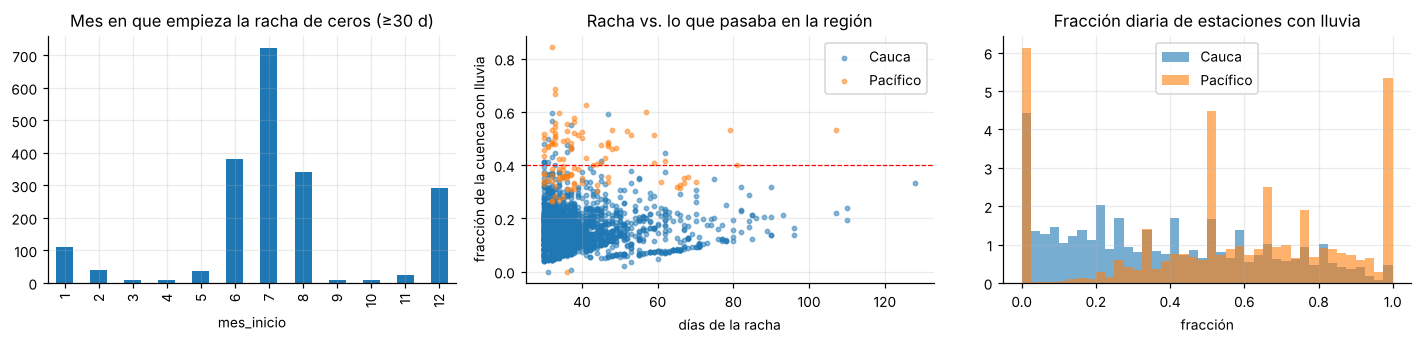

,STATION_ID,ini,fin,dias,cuenca,p_lluvia_region,racha_repetida,mes_inicio
1916,5301500104,1946-07-28,1946-08-28,32,Pacífico,0.843750,False,7
1918,5301500104,1954-05-07,1954-06-08,33,Pacífico,0.686869,False,5
1910,5301500102,1995-10-27,1995-11-28,33,Pacífico,0.666927,False,10
1902,5301500102,1974-12-15,1975-01-24,41,Pacífico,0.627316,True,12
1931,5420410112,1984-07-05,1984-08-30,57,Pacífico,0.599027,False,7
1887,5200000101,1993-08-18,1993-09-20,34,Pacífico,0.597629,False,8
119,2611200101,1956-05-14,1956-06-14,32,Cauca,0.596883,False,5
409,2612000114,1999-10-04,1999-11-19,47,Cauca,0.593448,False,10
1975,5421200207,1950-07-04,1950-08-10,38,Pacífico,0.578947,False,7
1408,2620610202,1970-05-15,1970-06-15,32,Cauca,0.567191,False,5


In [18]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
rz.mes_inicio.value_counts().sort_index().plot.bar(ax=ax[0], title="Mes en que empieza la racha de ceros (≥30 d)")
for c, g in rz.groupby("cuenca"):
    ax[1].scatter(g.dias, g.p_lluvia_region, s=8, alpha=.5, label=c)
ax[1].axhline(.4, color="red", ls="--", lw=.8); ax[1].legend()
ax[1].set(xlabel="días de la racha", ylabel="fracción de la cuenca con lluvia", title="Racha vs. lo que pasaba en la región")
ax[2].hist(hum.loc["Cauca"].eval("sum/count"), bins=40, alpha=.6, label="Cauca", density=True)
ax[2].hist(hum.loc["Pacífico"].eval("sum/count"), bins=40, alpha=.6, label="Pacífico", density=True)
ax[2].set(title="Fracción diaria de estaciones con lluvia", xlabel="fracción"); ax[2].legend()
plt.tight_layout(); plt.show()
display(rz.sort_values("p_lluvia_region", ascending=False).head(10))

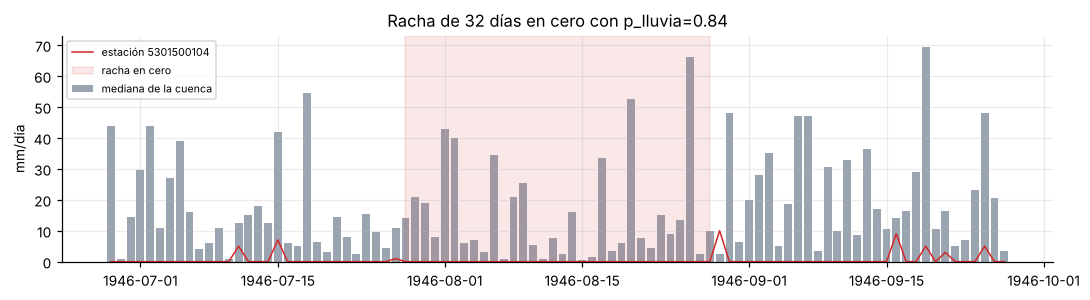

In [19]:
# Ejemplo: la racha más sospechosa vs. sus vecinas de cuenca
r0 = rz.sort_values("p_lluvia_region", ascending=False).iloc[0]
ventana = (pd.Timestamp(r0.ini) - pd.Timedelta(days=30), pd.Timestamp(r0.fin) + pd.Timedelta(days=30))
w = cal[(cal.cuenca == r0.cuenca) & cal.DATE.between(*ventana)]
med_reg = w[w.STATION_ID != r0.STATION_ID].groupby("DATE").VALUE.median()
propia = w[w.STATION_ID == r0.STATION_ID].set_index("DATE").VALUE
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.bar(med_reg.index, med_reg.values, color="#9aa5b1", label="mediana de la cuenca")
ax.plot(propia.index, propia.values, color="C3", lw=1, label=f"estación {r0.STATION_ID}")
ax.axvspan(pd.Timestamp(r0.ini), pd.Timestamp(r0.fin), color="C3", alpha=.1, label="racha en cero")
ax.set(title=f"Racha de {r0.dias} días en cero con p_lluvia={r0.p_lluvia_region:.2f}", ylabel="mm/día"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

In [20]:
# 6.3 Estación‑año completamente en cero y meses húmedos en cero
anio_cero = cal.dropna(subset=["VALUE"]).groupby(["STATION_ID", "YEAR"]).VALUE.agg(["count", "sum"])
anio_cero = anio_cero[(anio_cero["count"] >= 300) & (anio_cero["sum"] == 0)]
print("Estación‑año con ≥300 días y todos en cero:", len(anio_cero))
mh = mes[(mes.n_reg == mes.dias_mes) & mes.MONTH.isin([4, 5, 10, 11])]
print(f"Meses lluviosos (abr, may, oct, nov) completos y con total 0: {(mh.total == 0).sum()} de {len(mh)} "
      f"({100*(mh.total == 0).mean():.2f} %)")
display(mh[mh.total == 0].groupby("cuenca").size().rename("meses").to_frame().T)

Estación‑año con ≥300 días y todos en cero: 0
Meses lluviosos (abr, may, oct, nov) completos y con total 0: 8 de 31670 (0.03 %)


cuenca,Cauca,Pacífico
meses,7,1


**Lectura.**
- Hay ~2 000 rachas de ≥30 días en cero. **La mayoría son reales**: empiezan en junio‑agosto (la temporada seca de mitad de año) o en diciembre‑enero (la seca de inicio de año), en la cuenca del Cauca, y mientras ocurren solo ~10–20 % de las demás estaciones de la cuenca registran lluvia. Es el régimen bimodal visto desde los ceros.
- Las **sospechosas** son las que ocurren cuando la región sí llovía (`p_lluvia` ≥ 0,4): casi todas están en el **Pacífico**, donde una sequía de un mes es climatológicamente muy rara. El ejemplo graficado (5301500104, 1946) lo muestra: la cuenca llueve casi a diario y la estación marca 0 durante 32 días.
- No hay años enteros en cero ni casi meses de temporada lluviosa en cero (8 de 31 670): los ceros falsos no son masivos, son rachas puntuales.
- El umbral 0,4 es una propuesta: en el Cauca la fracción diaria de estaciones con lluvia rara vez supera 0,4 en temporada seca. Se puede afinar cuando se tengan coordenadas (vecinas a menos de X km en lugar de toda la cuenca).

## 7. Producto satelital

Los archivos `pptAAAANN.tif` tienen año (`AAAA`) y número de péntada (`NN` = 1…72). Se revisan metadatos, valores, nodata y la completitud de cada año.

In [21]:
tifs = sorted(p for p in SAT_DIR.glob("ppt*.tif") if not p.name.startswith("._"))
meta = pd.DataFrame({"archivo": [p.name for p in tifs]})
meta["anio"] = meta.archivo.str[3:7].astype(int); meta["pentada"] = meta.archivo.str[7:9].astype(int)
with rasterio.open(tifs[0]) as r:
    prof = r.profile; bounds = r.bounds; res = r.res
print("Archivos TIFF:", len(tifs), "| años:", meta.anio.min(), "–", meta.anio.max())
print("CRS:", prof["crs"].to_string(), "| tipo:", prof["dtype"], "| nodata:", prof["nodata"])
print(f"Malla: {prof['height']} filas × {prof['width']} columnas, resolución {res[0]:.3f}° (~{res[0]*111:.1f} km)")
print(f"Extensión: lon {bounds.left:.2f} a {bounds.right:.2f}, lat {bounds.bottom:.2f} a {bounds.top:.2f}")
cnt = meta.groupby("anio").size()
print("Años con 72 péntadas:", (cnt == 72).sum(), "| años incompletos:", cnt[cnt != 72].to_dict())
falt = [(y, p) for y in range(meta.anio.min(), meta.anio.max()+1) for p in range(1, 73)
        if not ((meta.anio == y) & (meta.pentada == p)).any()]
print("Péntadas ausentes (primeras):", falt[:5], "... total", len(falt))

Archivos TIFF: 2328 | años: 1981 – 2013
CRS: EPSG:4326 | tipo: int16 | nodata: -9999.0
Malla: 39 filas × 37 columnas, resolución 0.050° (~5.6 km)
Extensión: lon -77.55 a -75.70, lat 3.05 a 5.00
Años con 72 péntadas: 32 | años incompletos: {2013: 24}


Péntadas ausentes (primeras): [(2013, 25), (2013, 26), (2013, 27), (2013, 28), (2013, 29)] ... total 48


Forma del cubo: (2328, 39, 37) | NaN (nodata): 0
Píxeles siempre nodata: 0 de 1443
Valores: min 0, mediana 40, p99 163, max 200 mm/péntada; enteros: True; ceros: 7 celdas
Celdas exactamente en 200: 8,196 (0.24 %) vs. en 199: 327 y en 198: 344


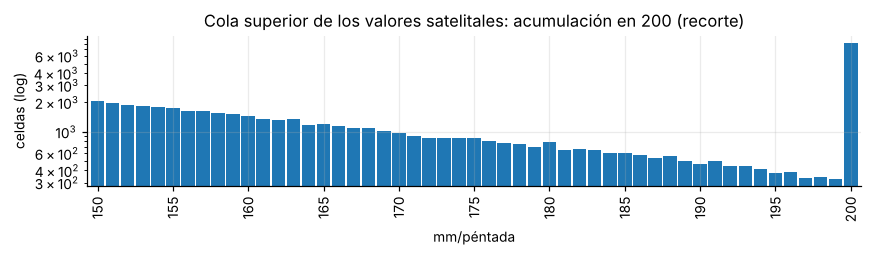

In [22]:
# Cubo completo: tiempo × lat × lon (2328 × 39 × 37, ~3 MB)
cubo = np.stack([rasterio.open(p).read(1).astype(float) for p in tifs])
cubo[cubo == prof["nodata"]] = np.nan
print("Forma del cubo:", cubo.shape, "| NaN (nodata):", int(np.isnan(cubo).sum()))
print("Píxeles siempre nodata:", int(np.isnan(cubo).all(0).sum()), "de", cubo.shape[1]*cubo.shape[2])
v = cubo[~np.isnan(cubo)]
print(f"Valores: min {v.min():.0f}, mediana {np.median(v):.0f}, p99 {np.percentile(v, 99):.0f}, max {v.max():.0f} mm/péntada; "
      f"enteros: {np.all(v % 1 == 0)}; ceros: {(v == 0).sum()} celdas")
vc = pd.Series(v).value_counts().sort_index()
print(f"Celdas exactamente en 200: {vc.get(200, 0):,} ({100*vc.get(200, 0)/len(v):.2f} %) vs. en 199: {vc.get(199, 0)} y en 198: {vc.get(198, 0)}")
fig, ax = plt.subplots(figsize=(8, 2.4))
vc.loc[150:].plot.bar(ax=ax, width=.9); ax.set_yscale("log")
ax.set_xticks(range(0, len(vc.loc[150:]), 5)); ax.set_xticklabels(vc.loc[150:].index[::5].astype(int))
ax.set(title="Cola superior de los valores satelitales: acumulación en 200 (recorte)", xlabel="mm/péntada", ylabel="celdas (log)")
plt.tight_layout(); plt.show()

**Lectura.** La malla es regular en WGS84 a 0,05° (~5,5 km), cubre lon −77,55 a −75,70 y lat 3,05 a 5,00 (el Valle del Cauca y su costa Pacífica), no tiene nodata ni píxeles vacíos y viene en **enteros**. Dos detalles importan para construir las curvas:

- **Recorte en 200 mm/péntada.** Hay miles de celdas exactamente en 200 y apenas cientos en 199, 198…: la distribución "choca" contra un techo. Es un **dato censurado** (el valor real es ≥200), casi siempre en el Pacífico en las péntadas más lluviosas. Si no se tiene en cuenta, el satélite **subestima los picos** en la costa y una parte del "sesgo satelital" que aprenda la KAN será un artefacto del recorte. Conviene marcar esas celdas y reportarlo.
- Las unidades son **mm acumulados en la péntada**, no mm/día (se ve en la siguiente gráfica).

In [23]:
# Días que tiene cada péntada (la 6.ª de cada mes va del día 26 al fin de mes)
def dias_pentada(anio, pent):
    mesp, k = (pent - 1) // 6 + 1, (pent - 1) % 6
    return 5 if k < 5 else pd.Timestamp(anio, mesp, 1).days_in_month - 25
def pentada_de(fecha):
    # Péntada (1‑72) de una serie de fechas: 6 por mes, la 6.ª del día 26 al fin de mes
    d = fecha.dt.day
    return (fecha.dt.month - 1) * 6 + np.minimum((d - 1) // 5, 5) + 1

meta["dias"] = [dias_pentada(a, p) for a, p in zip(meta.anio, meta.pentada)]
print("Días por péntada:", meta.dias.value_counts().sort_index().to_dict())
cubo_dia = cubo / meta.dias.values[:, None, None]      # mm/día

Días por péntada: {3: 25, 4: 8, 5: 2069, 6: 226}


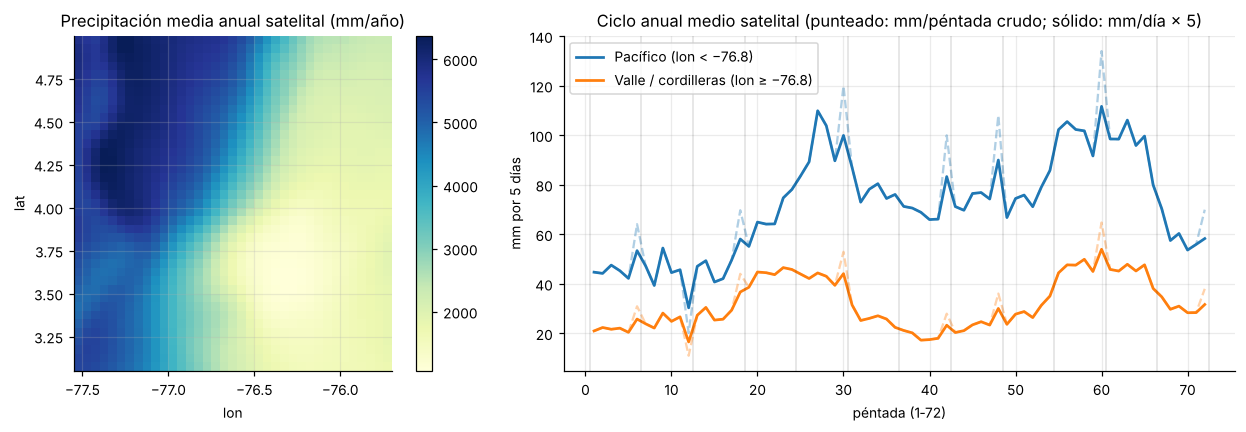

Media anual: min 1062, max 6371 mm/año


In [24]:
# Climatología espacial y ciclo anual
anios_comp = cnt[cnt == 72].index
sel = meta.anio.isin(anios_comp).values
anual = np.nansum(cubo[sel], axis=0) / len(anios_comp)          # mm/año medio
lon = bounds.left + res[0]*(np.arange(prof["width"]) + .5)
lat = bounds.top - res[1]*(np.arange(prof["height"]) + .5)

fig, ax = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 1.4]})
im = ax[0].pcolormesh(lon, lat, anual, cmap="YlGnBu", shading="auto")
ax[0].set(title="Precipitación media anual satelital (mm/año)", xlabel="lon", ylabel="lat"); ax[0].set_aspect("equal")
plt.colorbar(im, ax=ax[0])
oeste = lon < -76.8                                                # aprox. vertiente Pacífica
def ciclo_de(c):
    return pd.DataFrame({"pentada": meta.pentada[sel].values,
                         "Pacífico (lon < −76.8)": np.nanmean(c[sel][:, :, oeste], axis=(1, 2)),
                         "Valle / cordilleras (lon ≥ −76.8)": np.nanmean(c[sel][:, :, ~oeste], axis=(1, 2))}).groupby("pentada").mean()
ciclo_de(cubo).plot(ax=ax[1], alpha=.35, legend=False, style="--")
ax2 = ax[1]; c_dia = ciclo_de(cubo_dia) * 5
c_dia.plot(ax=ax2, lw=1.8, color=["C0", "C1"])
ax2.set(title="Ciclo anual medio satelital (punteado: mm/péntada crudo; sólido: mm/día × 5)", ylabel="mm por 5 días", xlabel="péntada (1‑72)")
for m in range(0, 73, 6): ax2.axvline(m+.5, color="k", lw=.3, alpha=.4)
plt.tight_layout(); plt.show()
print(f"Media anual: min {np.nanmin(anual):.0f}, max {np.nanmax(anual):.0f} mm/año")

**Lectura.**
- **Gradiente oeste‑este enorme**: de ~6000 mm/año en la vertiente Pacífica a ~1000–1500 mm/año en el valle del Cauca. Es la orografía: la cordillera Occidental frena los vientos húmedos del Pacífico (chorro del Chocó) y el valle queda en "sombra de lluvia". Un mismo modelo tiene que corregir sesgos en dos climas muy distintos.
- **Régimen bimodal** en el valle: máximos en abril‑mayo (péntadas ~19–30) y octubre‑noviembre (~55–66), mínimos en enero‑febrero y, sobre todo, julio‑agosto (péntadas ~38–46). En el Pacífico llueve todo el año con el mismo patrón superpuesto.
- **Artefacto de calendario (línea punteada):** los saltos en las péntadas 6, 18, 30, 42, 48, 60 y 72 y la caída en la 12 no son clima; son las 6.ª péntadas de los meses de 31 días (6 días de lluvia acumulada) y la de febrero (3–4 días). Al dividir por los días de cada péntada (línea sólida) desaparecen. **Conclusión: las curvas deben construirse en mm/día.**

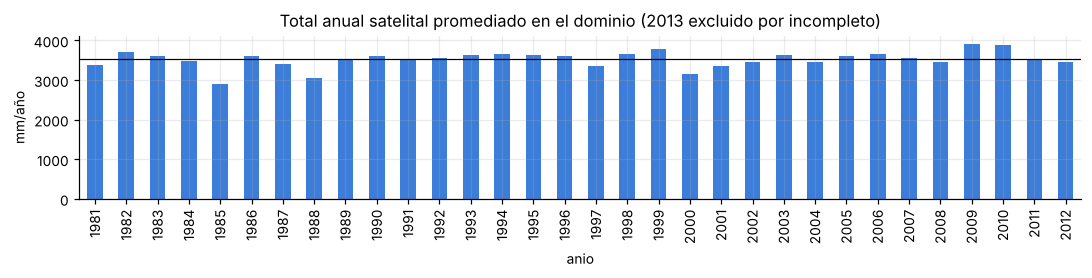

Años más secos: {1985: 2907.0, 1988: 3056.0, 2000: 3160.0, 1997: 3351.0}
Años más lluviosos: {2009: 3921.0, 2010: 3886.0, 1999: 3777.0, 1982: 3701.0}


In [25]:
# Serie anual satelital (promedio del dominio) para ver años anómalos (ENSO)
ser = pd.Series(np.nanmean(cubo, axis=(1, 2)), index=meta.set_index(["anio", "pentada"]).index).groupby("anio").sum()
fig, ax = plt.subplots(figsize=(10, 2.6))
ser.loc[anios_comp].plot.bar(ax=ax, color="#3b7dd8")
ax.axhline(ser.loc[anios_comp].mean(), color="k", lw=.8)
ax.set(title="Total anual satelital promediado en el dominio (2013 excluido por incompleto)", ylabel="mm/año"); plt.tight_layout(); plt.show()
print("Años más secos:", ser.loc[anios_comp].nsmallest(4).round(0).to_dict())
print("Años más lluviosos:", ser.loc[anios_comp].nlargest(4).round(0).to_dict())

**Lectura.** Llaman la atención **1985, 1988 y 2000**: el satélite los marca como los años más secos de todo el registro, en la costa y en el valle. Pero 1988–89 y 1999–2000 fueron años **La Niña**, que en el occidente colombiano suelen traer *más* lluvia, no menos. Antes de interpretarlo como clima hay que contrastarlo con las estaciones (se hace en la §9.1). Para reportar resultados por fase ENSO hará falta el **índice ONI** (NOAA), que no viene en los archivos.

### 7.1 Verificación independiente de los ceros sospechosos con el satélite

En la §6 el contraste de los ceros se hizo contra otras estaciones. El satélite permite un contraste **independiente** para las rachas desde 1981: si la estación marca 30+ días en cero pero el satélite muestra lluvia normal para esa época en la región, el cero es poco creíble. Se calcula la razón *lluvia satelital durante la racha / lluvia satelital climatológica de esas mismas péntadas* en la región de la estación (Pacífico u oriente). Una razón cercana a 0 respalda una sequía real; una razón ≈1 o mayor sugiere un cero falso.

Rachas ≥30 d desde 1981 con contraste satelital: 1291


,count,mean,std,min,25%,50%,75%,max
contraste_estaciones,,,,,,,,
"región también seca (p<0,4)",1246.0,0.85,0.15,0.49,0.75,0.86,0.97,1.28
"sospechosa (p≥0,4)",45.0,0.91,0.11,0.56,0.84,0.93,0.98,1.11


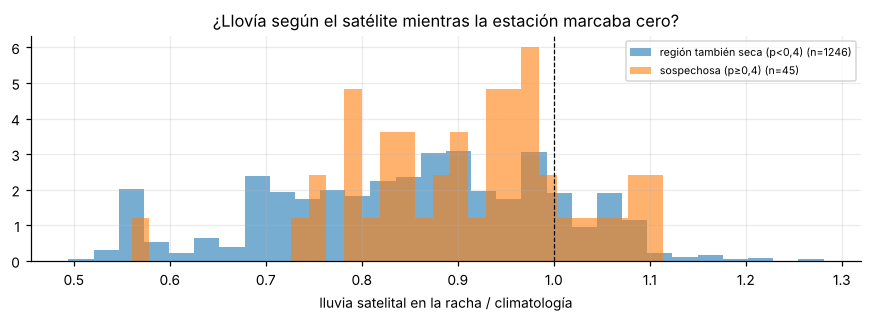

In [26]:
# mm/día satelital regional por péntada y su climatología
reg = pd.DataFrame({"anio": meta.anio, "pentada": meta.pentada,
                    "Pacífico": np.nanmean(cubo_dia[:, :, oeste], axis=(1, 2)),
                    "Cauca": np.nanmean(cubo_dia[:, :, ~oeste], axis=(1, 2))})
clim_reg = reg[reg.anio.isin(anios_comp)].groupby("pentada")[["Pacífico", "Cauca"]].mean()

def razon_sat(r):
    dias = pd.date_range(r.ini, r.fin)
    if dias[0].year < 1981 or dias[-1].year > 2012: return np.nan
    p = pd.DataFrame({"anio": dias.year, "pentada": pentada_de(pd.Series(dias)).values})
    obs = p.merge(reg, on=["anio", "pentada"])[r.cuenca].mean()
    ref = clim_reg.loc[p.pentada, r.cuenca].mean()
    return obs / ref

rz["razon_sat"] = rz.apply(razon_sat, axis=1)
rs = rz.dropna(subset=["razon_sat"]).copy()
rs["contraste_estaciones"] = np.where(rs.p_lluvia_region >= .4, "sospechosa (p≥0,4)", "región también seca (p<0,4)")
print(f"Rachas ≥30 d desde 1981 con contraste satelital: {len(rs)}")
display(rs.groupby("contraste_estaciones").razon_sat.describe().round(2))
fig, ax = plt.subplots(figsize=(8, 3))
for k, g in rs.groupby("contraste_estaciones"):
    ax.hist(g.razon_sat, bins=30, alpha=.6, label=f"{k} (n={len(g)})", density=True)
ax.axvline(1, color="k", lw=.8, ls="--")
ax.set(xlabel="lluvia satelital en la racha / climatología", title="¿Llovía según el satélite mientras la estación marcaba cero?")
ax.legend(fontsize=7); plt.tight_layout(); plt.show()

In [27]:
# Las rachas con fechas idénticas en muchas estaciones: ¿error masivo o sequía regional?
grupos = (rz.groupby(["ini", "fin"]).agg(estaciones=("STATION_ID", "size"), dias=("dias", "first"),
                                         p_lluvia=("p_lluvia_region", "mean"), razon_sat=("razon_sat", "mean"))
            .reset_index().sort_values("estaciones", ascending=False))
display(grupos.head(8).round(2))

/tmp/ipykernel_1331/1322045257.py:5: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(grupos.head(8).round(2))


,ini,fin,estaciones,dias,p_lluvia,razon_sat
989,1991-08-10,1991-09-14,25,36,0.09,0.57
984,1991-08-09,1991-09-14,22,37,0.09,0.57
355,1976-08-20,1976-09-23,12,35,0.12,NaN
818,1986-07-17,1986-08-15,10,30,0.09,0.89
320,1976-07-05,1976-08-06,9,33,0.10,NaN
657,1982-08-08,1982-09-09,9,33,0.06,0.87
988,1991-08-10,1991-09-13,8,35,0.10,0.57
1207,1997-07-01,1997-09-04,8,66,0.11,0.96


**Lectura.**
- El satélite **no discrimina** bien entre rachas reales y sospechosas a esta escala (razón ~0,85–0,9 en ambos grupos). Hay dos motivos: (1) aquí se usa el promedio de toda una región, no el píxel de la estación (no tenemos coordenadas), y (2) **el satélite casi nunca marca cero** (solo 7 celdas de 3,3 millones): en temporada seca reporta llovizna donde los pluviómetros marcan 0. Esto ya es un primer indicio del **sesgo satelital**: sobreestima la lluvia en los periodos secos.
- Las rachas con **fechas idénticas en muchas estaciones** (25 estaciones del 10/08 al 14/09/1991; 8 estaciones de julio a septiembre de 1997) **no son errores**: son sequías regionales en años **El Niño** (1991‑92 y 1997‑98), con la región seca (`p_lluvia` ≈ 0,1) y el satélite por debajo de lo normal en 1991 (razón 0,57). Se conservan.
- La verificación con satélite debe repetirse con el **píxel** de cada estación cuando se tengan coordenadas.

## 8. Periodo común y dominio anual de las curvas

Las dos fuentes deben construirse **sobre el mismo dominio anual** (rúbrica, ítem 1). Puntos a decidir:

- **Periodo común real.** El satélite va de 1981 a 2013, pero las estaciones **terminan en 2003**. El emparejamiento estación–satélite solo es posible en **1981–2003 (23 años)**. Los años 2004–2012 del satélite pueden servir para describir el satélite, pero no para comparar ni entrenar la KAN. 2013 tiene solo 24 péntadas (hasta finales de abril): se excluye.
- **Datos fuera del periodo.** 1930–1980 tiene estaciones pero no satélite. El enunciado permite usarlos, por ejemplo, para estimar mejor el FPCA de las estaciones (más curvas → funciones propias más estables). Si se hace, debe quedar fuera de cualquier conjunto de prueba.
- **Péntadas vs. días.** Cada mes tiene 6 péntadas: días 1–5, 6–10, 11–15, 16–20, 21–25 y 26–fin de mes (la 6.ª tiene 3 a 6 días). Por eso conviene expresar ambas fuentes en **mm/día** sobre el **día del año** (centro de cada péntada), o agregar las estaciones a péntadas con la misma regla.
- **29 de febrero.** Años de 366 días vs. 365: se puede eliminar el 29/02 o reescalar el dominio a [0, 1]. Para las péntadas no importa (la 12.ª péntada absorbe el 29).

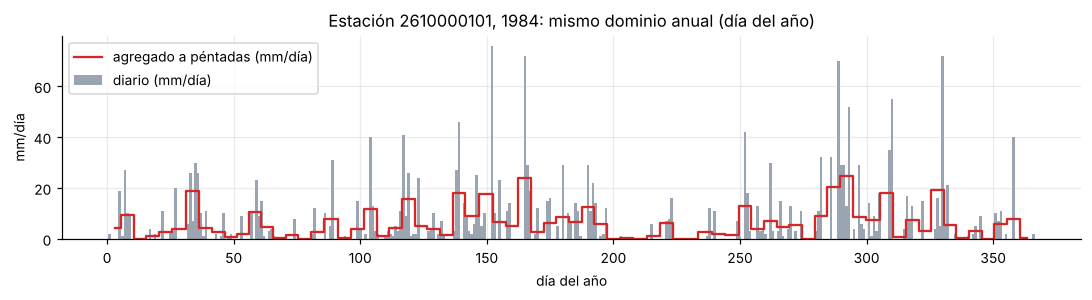

Días por péntada: {4: 1, 5: 64, 6: 7}


In [28]:
# Ejemplo: una estación‑año completa del valle agregada a péntadas vs. su día a día
ej = cob.query("1981 <= YEAR <= 2003 and cobertura == 1 and cuenca == 'Cauca'").iloc[0]
s = cal[(cal.STATION_ID == ej.STATION_ID) & (cal.YEAR == ej.YEAR)].copy()
s["pent"] = pentada_de(s.DATE)
pp = s.groupby("pent").agg(mm=("VALUE", "sum"), dias=("VALUE", "size"), doy=("doy", "mean"))
pp["mm_dia"] = pp.mm / pp.dias
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.bar(s.doy, s.VALUE, width=1, color="#9aa5b1", label="diario (mm/día)")
ax.step(pp.doy, pp.mm_dia, where="mid", color="C3", lw=1.5, label="agregado a péntadas (mm/día)")
ax.set(title=f"Estación {ej.STATION_ID}, {ej.YEAR}: mismo dominio anual (día del año)", xlabel="día del año", ylabel="mm/día")
ax.legend(); plt.tight_layout(); plt.show()
print("Días por péntada:", pp.dias.value_counts().sort_index().to_dict())

## 9. ¿Qué podríamos hacer? Embudo preliminar de depuración (1981–2003)

Se aplican en orden los pasos propuestos y, después de cada uno, se cuentan **estaciones** y **pares estación‑año** que siguen siendo utilizables. Los umbrales son una propuesta inicial para discutir; la tabla de sensibilidad del final ayuda a justificarlos.

| Paso | Regla propuesta | Por qué |
|---|---|---|
| P0 | Todos los registros 1981–2003 | Punto de partida: periodo con ambas fuentes |
| P1 | Valores > 500 mm/día que **no** sean total mensual → faltante | Físicamente imposibles para un día en la región (ver §3) |
| P2 | Mes con un único registro → mes faltante | Es un total mensual, no un dato diario (§4) |
| P3 | Años copiados entre estaciones → faltantes en todas las copias | No se sabe cuál es la original (§6.1) |
| P4 | Rachas de ≥30 ceros con `p_lluvia_region` ≥ 0,4 → faltante | La región llovía; el cero no es creíble (§6.2) |
| P5 | Cobertura del año ≥ 90 % **y** ningún hueco > 30 días **y** 12 meses con ≥ 20 días | Que la curva anual quede bien determinada en todo el dominio, incluidas las dos temporadas de lluvia |
| P6 | Estación con ≥ 10 años válidos | Suficientes curvas por estación para dividir en entrenamiento/prueba temporal |

In [29]:
D = cal[(cal.YEAR >= 1981) & (cal.YEAR <= 2003)][["STATION_ID", "DATE", "YEAR", "MONTH", "VALUE", "cuenca"]].copy()
# Se completan años calendario enteros para cada estación‑año presente
pares = D.dropna(subset=["VALUE"])[["STATION_ID", "YEAR"]].drop_duplicates()
full = pd.concat([pd.DataFrame({"STATION_ID": s, "DATE": pd.date_range(f"{y}-01-01", f"{y}-12-31")}) for s, y in pares.itertuples(index=False)])
D = full.merge(D[["STATION_ID", "DATE", "VALUE"]], on=["STATION_ID", "DATE"], how="left")
D["YEAR"], D["MONTH"] = D.DATE.dt.year, D.DATE.dt.month
D["flag"] = ""

def conteo(paso, df, criterio_valido=None):
    v = df.dropna(subset=["VALUE"])
    return {"paso": paso, "estaciones": v.STATION_ID.nunique(),
            "pares_estacion_anio": v[["STATION_ID", "YEAR"]].drop_duplicates().shape[0],
            "dias_con_dato": len(v)}
emb = [conteo("P0 crudo 1981‑2003", D)]

# P2 antes que P1 para no confundir totales mensuales con errores
k = D.merge(uno[["STATION_ID", "YEAR", "MONTH"]], on=["STATION_ID", "YEAR", "MONTH"], how="left", indicator=True)._merge.eq("both").values
D.loc[k & D.VALUE.notna(), "flag"] = "total_mensual"
m1 = (D.VALUE > 500) & (D.flag == "")
D.loc[m1, "flag"] = "imposible"
D.loc[D.flag == "imposible", "VALUE"] = np.nan;     emb.append(conteo("P1 valores imposibles", D))
D.loc[D.flag == "total_mensual", "VALUE"] = np.nan; emb.append(conteo("P2 totales mensuales", D))

cp = D.merge(copias[["STATION_ID", "YEAR"]], on=["STATION_ID", "YEAR"], how="left", indicator=True)._merge.eq("both").values
D.loc[cp & D.VALUE.notna(), "flag"] = "anio_copiado"; D.loc[cp, "VALUE"] = np.nan
emb.append(conteo("P3 años copiados", D))

sosp = rz[rz.p_lluvia_region >= .4]
for r in sosp.itertuples():
    m = (D.STATION_ID == r.STATION_ID) & D.DATE.between(r.ini, r.fin)
    D.loc[m & D.VALUE.notna(), "flag"] = "cero_falso"; D.loc[m, "VALUE"] = np.nan
emb.append(conteo("P4 ceros falsos", D))

def resumen_anio(g):
    falta = g.VALUE.isna().values
    return pd.Series({"cob": 1 - falta.mean(), "hueco": max_racha(falta),
                      "meses20": int((g.groupby("MONTH").VALUE.count() >= 20).sum())})
ra = D.groupby(["STATION_ID", "YEAR"]).apply(resumen_anio).reset_index()
ra["ok"] = (ra.cob >= .90) & (ra.hueco <= 30) & (ra.meses20 == 12)
validos = ra[ra.ok]
emb.append({"paso": "P5 cobertura ≥90 %, hueco ≤30 d, 12 meses", "estaciones": validos.STATION_ID.nunique(),
            "pares_estacion_anio": len(validos), "dias_con_dato": np.nan})
n_anios = validos.groupby("STATION_ID").size()
validos6 = validos[validos.STATION_ID.isin(n_anios[n_anios >= 10].index)]
emb.append({"paso": "P6 estaciones con ≥10 años válidos", "estaciones": validos6.STATION_ID.nunique(),
            "pares_estacion_anio": len(validos6), "dias_con_dato": np.nan})
emb = pd.DataFrame(emb); display(emb)
print("Días marcados por tipo:", D.flag.value_counts().drop("", errors="ignore").to_dict())

,paso,estaciones,pares_estacion_anio,dias_con_dato
0,P0 crudo 1981‑2003,323,5514,1930611.0
1,P1 valores imposibles,323,5514,1930607.0
2,P2 totales mensuales,322,5513,1930550.0
3,P3 años copiados,322,5511,1929944.0
4,P4 ceros falsos,322,5511,1927994.0
5,"P5 cobertura ≥90 %, hueco ≤30 d, 12 meses",309,4744,NaN
6,P6 estaciones con ≥10 años válidos,238,4426,NaN


Días marcados por tipo: {'cero_falso': 1950, 'anio_copiado': 606, 'total_mensual': 57, 'imposible': 4}


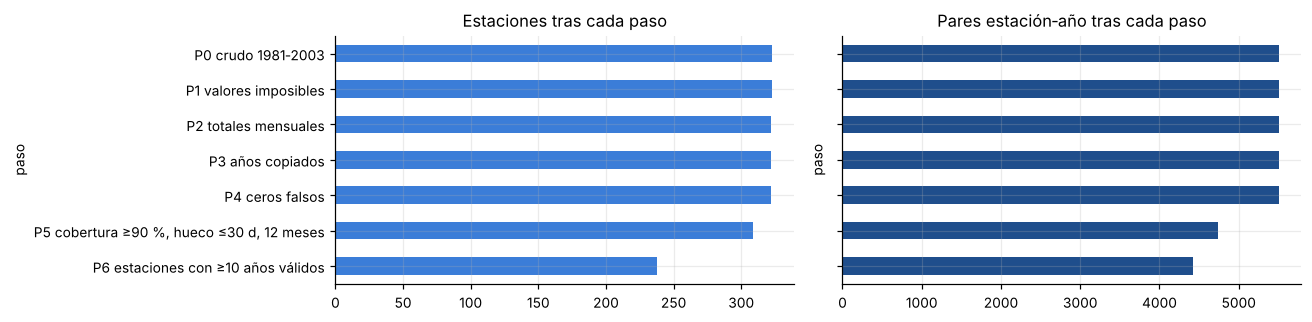

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3))
emb.set_index("paso").estaciones.plot.barh(ax=ax[0], title="Estaciones tras cada paso", color="#3b7dd8"); ax[0].invert_yaxis()
emb.set_index("paso").pares_estacion_anio.plot.barh(ax=ax[1], title="Pares estación‑año tras cada paso", color="#1f4e8c"); ax[1].invert_yaxis()
ax[1].set_yticklabels([]); plt.tight_layout(); plt.show()

In [31]:
# Sensibilidad del criterio de cobertura: ¿cuánto se pierde con cada umbral?
filas = []
for exigir_meses in [False, True]:
    for c in [.70, .80, .90, .95, 1.0]:
        for h in [15, 30, 60]:
            v = ra[(ra.cob >= c) & (ra.hueco <= h) & ((ra.meses20 == 12) | (not exigir_meses))]
            n = v.groupby("STATION_ID").size()
            filas.append({"12 meses con ≥20 días": "sí" if exigir_meses else "no", "cobertura_min": f"{c:.0%}",
                          "hueco_max_d": h, "pares": len(v), "estaciones_≥10_años": int((n >= 10).sum())})
sens = pd.DataFrame(filas)
display(sens.pivot_table(index=["12 meses con ≥20 días", "cobertura_min"], columns="hueco_max_d",
                         values=["pares", "estaciones_≥10_años"], sort=False).astype(int))

pares             estaciones_≥10_años          
hueco_max_d                            15    30    60                  15   30   60
12 meses con ≥20 días cobertura_min                                                
no                    70%            4806  4938  5150                 239  244  249
                      80%            4803  4932  5130                 239  244  249
                      90%            4794  4908  5012                 239  243  245
                      95%            4759  4774  4774                 238  238  238
                      100%           4006  4006  4006                 209  209  209
sí                    70%            4743  4744  4744                 238  238  238
                      80%            4743  4744  4744                 238  238  238
                      90%            4743  4744  4744                 238  238  238
                      95%            4727  4728  4728                 238  238  238
                      100%           4006  4006  4006                 209  209  209

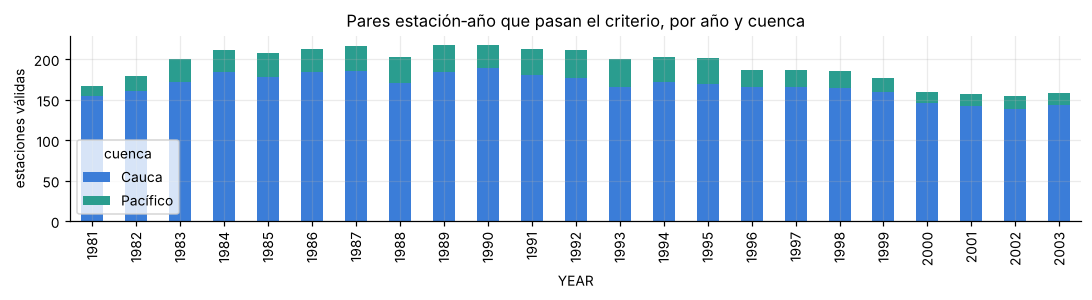

,estaciones,pares
cuenca,,
Cauca,199,3856
Pacífico,39,570


In [32]:
# ¿El criterio deja años de todo el periodo y ambas cuencas? (riesgo de sesgo temporal o regional)
validos6 = validos6.assign(cuenca=np.where(validos6.STATION_ID.astype(str).str[:2] == "26", "Cauca", "Pacífico"))
fig, ax = plt.subplots(figsize=(10, 2.8))
validos6.groupby(["YEAR", "cuenca"]).size().unstack().plot.bar(stacked=True, ax=ax, color=["#3b7dd8", "#2a9d8f"])
ax.set(title="Pares estación‑año que pasan el criterio, por año y cuenca", ylabel="estaciones válidas"); plt.tight_layout(); plt.show()
display(validos6.groupby("cuenca").agg(estaciones=("STATION_ID", "nunique"), pares=("YEAR", "size")))

**Lectura del embudo.**
- Las correcciones de valores (P1–P4) **casi no cambian los conteos** de estaciones ni de pares estación‑año: los errores están concentrados y en 1981–2003 afectan pocos días (4 imposibles, 57 de totales mensuales, ~600 de años copiados, ~2 000 de ceros falsos). Su importancia está en la **forma de las curvas**: un solo valor de 859 375 mm o un total mensual de 900 mm en un día arruinan el suavizado de ese año.
- El paso que más recorta es **la cobertura** (P5: de 5 511 a ~4 740 pares) y luego **exigir ≥10 años por estación** (P6: de 309 a 238 estaciones).
- **Sensibilidad:** sin exigir los 12 meses, los umbrales sí importan (con 70 % de cobertura entran ~160 pares más que con 95 % si el hueco máximo es 30 días, y ~380 más si es 60). En cambio, **una vez se exige que cada mes tenga ≥20 días con dato, el umbral de cobertura y el de hueco máximo casi dejan de importar**: los resultados son prácticamente iguales entre 70 % y 95 %. Esa es una buena justificación del criterio: lo que protege la curva es que **no falte ningún tramo del año** (en particular las dos temporadas de lluvia), y esa regla es estable.
- Con el criterio preliminar quedan **238 estaciones y 4 426 pares estación‑año** (199 del Cauca y 39 del Pacífico), con todos los años 1981–2003 representados (entre ~155 y ~220 estaciones por año). El Pacífico queda menos representado: hay que tenerlo en cuenta al interpretar resultados por subregión.

### 9.1 ¿Satélite y estaciones cuentan la misma historia año a año?

Con los pares estación‑año que pasan el criterio se calcula, para cada estación, la anomalía estandarizada de su lluvia anual (z respecto a su propia media) y se toma la mediana por año y cuenca. Se compara con la anomalía estandarizada del total anual satelital de la región correspondiente (oeste de −76,8° ≈ Pacífico, este ≈ valle). Es una comparación gruesa (sin emparejar píxeles), pero basta para ver si los años "raros" del satélite aparecen también en tierra.

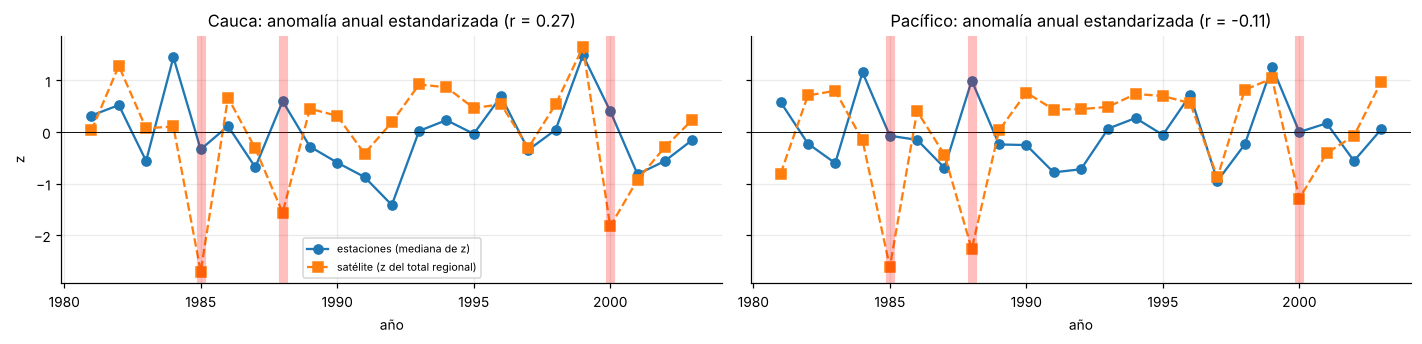

estaciones          satélite      
          Cauca Pacífico Pacífico Cauca
1985      -0.34    -0.07    -2.62 -2.70
1988       0.60     1.00    -2.27 -1.56
1991      -0.87    -0.78     0.44 -0.42
1992      -1.41    -0.72     0.44  0.19
1997      -0.35    -0.95    -0.87 -0.30
1999       1.49     1.27     1.04  1.65
2000       0.41     0.00    -1.29 -1.83

In [33]:
x = raw[raw.YEAR.between(1981, 2003) & (raw.VALUE <= 500)].merge(validos6[["STATION_ID", "YEAR"]], on=["STATION_ID", "YEAR"])
tot = x.groupby(["STATION_ID", "YEAR", "cuenca"]).VALUE.mean().mul(365).rename("anual").reset_index()
tot["z"] = tot.groupby("STATION_ID").anual.transform(lambda s: (s - s.mean()) / s.std())
z_est = tot.groupby(["YEAR", "cuenca"]).z.median().unstack()
sat_reg = (pd.DataFrame({"anio": meta.anio, "Pacífico": np.nanmean(cubo[:, :, oeste], axis=(1, 2)),
                         "Cauca": np.nanmean(cubo[:, :, ~oeste], axis=(1, 2))})
             .groupby("anio").sum().loc[1981:2003])
z_sat = (sat_reg - sat_reg.mean()) / sat_reg.std()

fig, ax = plt.subplots(1, 2, figsize=(13, 3.2), sharey=True)
for a, cu in zip(ax, ["Cauca", "Pacífico"]):
    a.plot(z_est.index, z_est[cu], "o-", label="estaciones (mediana de z)")
    a.plot(z_sat.index, z_sat[cu], "s--", label="satélite (z del total regional)")
    a.axhline(0, color="k", lw=.6)
    for y in [1985, 1988, 2000]: a.axvline(y, color="red", alpha=.25, lw=6)
    a.set(title=f"{cu}: anomalía anual estandarizada (r = {z_est[cu].corr(z_sat[cu]):.2f})", xlabel="año")
ax[0].set_ylabel("z"); ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()
display(pd.concat({"estaciones": z_est, "satélite": z_sat}, axis=1).loc[[1985, 1988, 1991, 1992, 1997, 1999, 2000]].round(2))

**Lectura.** Esta es probablemente la observación más importante del EDA para el resto del proyecto:

- **Año a año, las dos fuentes concuerdan poco** (correlación ≈0,3 en el valle y ≈0 en el Pacífico).
- En **1985, 1988 y 2000** el satélite muestra déficits de −1,5 a −2,7 desviaciones estándar, y **las estaciones no los ven**: en 1988 (La Niña) las estaciones están *por encima* de lo normal. A la inversa, **1991–1992** (El Niño) es seco en las estaciones y normal en el satélite. Las estaciones, que son lo que esperaríamos climatológicamente (El Niño seco, La Niña húmedo), resultan más coherentes con ENSO que el satélite.
- Interpretación: **inhomogeneidades del producto satelital entregado**, no clima. Se **confirmó** en `02_datos_externos.ipynb`: el CHIRPS v2 original (misma malla y péntadas) no tiene esos déficits; en 1985, 1988 y 2000 el producto entregado queda 25–35 % por debajo de CHIRPS v2 en la costa y 8–14 % en el valle, mientras que en 1982, 1990 y 1997 ambos coinciden. Además, según el ONI, 1985, 1988 y 2000 fueron años La Niña. Para el proyecto significa que el **sesgo satelital no es solo estacional, también depende del año**. Esos años deberían aparecer como curvas atípicas del satélite en el boxplot funcional (ítem 2) y pueden pesar mucho en el entrenamiento de la KAN, así que hay que decidir conscientemente si se tratan como atípicos o se dejan.
- Esto debe repetirse con el emparejamiento estación–píxel cuando se tengan coordenadas.

## 10. Síntesis: problemas encontrados y qué hacer

| # | Problema | Evidencia | Propuesta | Dónde |
|---|---|---|---|---|
| 1 | **Faltantes implícitos** (días que no existen, no `NaN`) | 0 nulos explícitos; 19 % de pares estación‑año 1981–2003 incompletos, casi siempre con huecos >30 días | Reconstruir calendario; criterio de cobertura (P5) | §5 |
| 2 | **Valor imposible** | 859 375 mm (2611600101, 10/01/1984); 600 mm aislado en 2614400105 (2003) | Faltante | §3 |
| 3 | **Totales mensuales en un día** | 212 meses con un solo registro, 89 % en el último día, valor ≈ total mensual | Mes faltante (u opcional: desagregar con vecinas) | §4 |
| 4 | **Acumulados tras hueco** | 426 días > p99 después de ≥3 días sin registro | Solo bandera; revisar caso a caso | §4 |
| 5 | **Años copiados entre estaciones** | 12 pares estación‑año idénticos (incluso Cauca = Pacífico) | Eliminar todas las copias | §6.1 |
| 6 | **Ceros falsos** | Rachas ≥30 d en cero con la región lloviendo (`p_lluvia` ≥ 0,4), sobre todo en el Pacífico | Faltante en la racha | §6.2 |
| 7 | **Redondeo a 1 mm** | 98,8 % enteros; decimales solo en algunas estaciones/años | Umbral de día lluvioso ≥1 mm | §2.2 |
| 8 | **Satélite en mm/péntada con péntadas de 3–6 días** | Saltos en péntadas 6, 12, 18, 30… | Pasar a **mm/día** antes de suavizar | §7 |
| 9 | **Satélite recortado en 200 mm/péntada** | 8 196 celdas en 200 vs ~330 en 199 | Marcar como censurado; reportar; cuidado en el Pacífico | §7 |
| 10 | **Satélite casi nunca en cero** | 7 celdas en cero de 3,3 M | Es parte del sesgo a corregir (llovizna en temporada seca) | §7.1 |
| 11 | **Periodo común real 1981–2003** | Estaciones terminan en 2003; satélite 2013 incompleto (24 péntadas) | Emparejar y modelar en 1981–2003; 2004–2012 solo para describir el satélite; 2013 fuera | §2, §8 |
| 12 | **Dominio anual** | Diario (365/366) vs. 72 péntadas | Ambas en mm/día sobre día del año; tratar el 29/02 | §8 |
| 13 | **Años anómalos solo en el satélite** | 1985, 1988, 2000 muy secos en satélite y normales/húmedos en estaciones; r interanual ≈0,3 | Tratarlos como posibles atípicos del satélite; verificar con píxel; considerar en el análisis por ENSO | §9.1 |

### Información externa (ver `02_datos_externos.ipynb`)

- **Coordenadas y altitud de las estaciones: no se pueden obtener de fuentes públicas.** Los códigos del proyecto (10 dígitos) no corresponden al Catálogo Nacional de Estaciones (8 dígitos) ni aparecen en la web. Sin ellas no hay emparejamiento estación–píxel (ítem 3: tope de nota 2) ni altitud para `z`. **Hay que pedir al docente la tabla `STATION_ID → lat, lon, altitud`.**
- **Índice ONI**: descargado de NOAA CPC (`datos_web/ONI_NOAA_CPC_1981_2013.csv`).
- **Rellenar huecos con datos de la web no es viable** para 1981–2003: el IDEAM en datos.gov.co solo publica 2017–2026, la descarga histórica no responde y no hay mapa de códigos.

### Decisiones abiertas para la fase de preprocesamiento

1. Confirmar los umbrales (500 mm/día, `p_lluvia` ≥ 0,4, cobertura ≥90 % + hueco ≤30 d + 12 meses con ≥20 días, ≥10 años por estación).
2. ¿Imputar los huecos cortos o dejar que la base B‑spline los absorba? Con la regla de 12 meses, los huecos que quedan son cortos; el suavizado por mínimos cuadrados funciona con puntos irregulares, así que **no imputar** es defendible.
3. ¿Usar 1930–1980 para estimar el FPCA de las estaciones? Da más curvas (más estabilidad), pero mezcla otra época. Si se usa, **solo en el conjunto de entrenamiento**.
4. Toda decisión con umbrales debe fijarse **sin mirar los años/estaciones de prueba** (rúbrica 4.1 y 4.4). Este EDA describe todos los datos, pero los umbrales finales conviene recalcularlos solo con la partición de entrenamiento.

Las tablas de banderas y del embudo quedaron en `eda_fase0/` para usarlas en la siguiente fase.

In [34]:
# Guardar tablas para las fases siguientes
uno.to_csv(OUT / "totales_mensuales_un_dia.csv", index=False)
copias.to_csv(OUT / "anios_copiados_entre_estaciones.csv", index=False)
rz.to_csv(OUT / "rachas_ceros_30d_con_contraste_regional.csv", index=False)
cob.to_csv(OUT / "cobertura_estacion_anio_todo_el_registro.csv", index=False)
ra.to_csv(OUT / "cobertura_estacion_anio_1981_2003_tras_depuracion.csv", index=False)
emb.to_csv(OUT / "embudo_depuracion_preliminar.csv", index=False)
D.loc[D.flag != "", ["STATION_ID", "DATE", "flag"]].to_csv(OUT / "dias_marcados.csv", index=False)
validos6[["STATION_ID", "YEAR", "cuenca"]].to_csv(OUT / "pares_estacion_anio_validos_preliminar.csv", index=False)
print(sorted(p.name for p in OUT.glob("*.csv")))

['anios_copiados_entre_estaciones.csv', 'anomalias_anuales_est_entregado_chirpsv2.csv', 'cobertura_estacion_anio_1981_2003_tras_depuracion.csv', 'cobertura_estacion_anio_todo_el_registro.csv', 'dias_marcados.csv', 'embudo_depuracion_preliminar.csv', 'oni_anual_fase.csv', 'pares_estacion_anio_validos_preliminar.csv', 'rachas_ceros_30d_con_contraste_regional.csv', 'totales_mensuales_un_dia.csv']
